In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
from tqdm import trange

from dualwcfm.trainers.dual_trainer import DualTrainer, DualTrainerConfig
from dualwcfm.visualization import plot_2d_flow_trajectories
from dualwcfm.models.cfm import ConditionalFlowMatching
from dualwcfm.trainers.dynamic_trainer import DynamicTrainer
from dualwcfm.models.cfm import torch_wrapper
from dualwcfm.trainers.wcfm import CFMTrainerConfig
from torchcfm.models.models import MLP
from dualwcfm.distributions.distribution import Distribution
from dualwcfm.distributions.coupling import FixedSizeCouplingDistribution, FunctionalCouplingDistribution
from dualwcfm.distributions import CouplingDistribution, RotatedShapeCoupling, Simple2DGaussianDistribution, RotatedDistribution, MoonDistribution

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [33]:
import torch
import torch.nn as nn
from torchdyn.core import NeuralODE

class LagrangianFlowField(nn.Module):
    """
    Wraps a velocity network to handle 'Source Conditioning'.
    State z = [x_t, x_0] (Dimension 2*D)
    Dynamics: dx/dt = net(x_t, x_0, t), dx_0/dt = 0
    """
    def __init__(self, net, dim):
        super().__init__()
        self.net = net
        self.dim = dim

    def forward(self, x):
        x_t = x[:, :self.dim]      # Current Position (Evolving)
        x_0 = x[:, self.dim:2*self.dim]      # Initial Position (Constant Context)

        # if isinstance(t, torch.Tensor) and t.dim() == 0:
        #      t = t.repeat(z.shape[0], 1)
        # elif isinstance(t, float):
        #      t = torch.full((z.shape[0], 1), t).to(z.device)

        # net_input = torch.cat([x_t, x_0, t], dim=1)

        v_x = self.net(x)
        v_c = torch.zeros_like(x_0)
        return torch.cat([v_x, v_c], dim=1)

<Figure size 800x800 with 0 Axes>

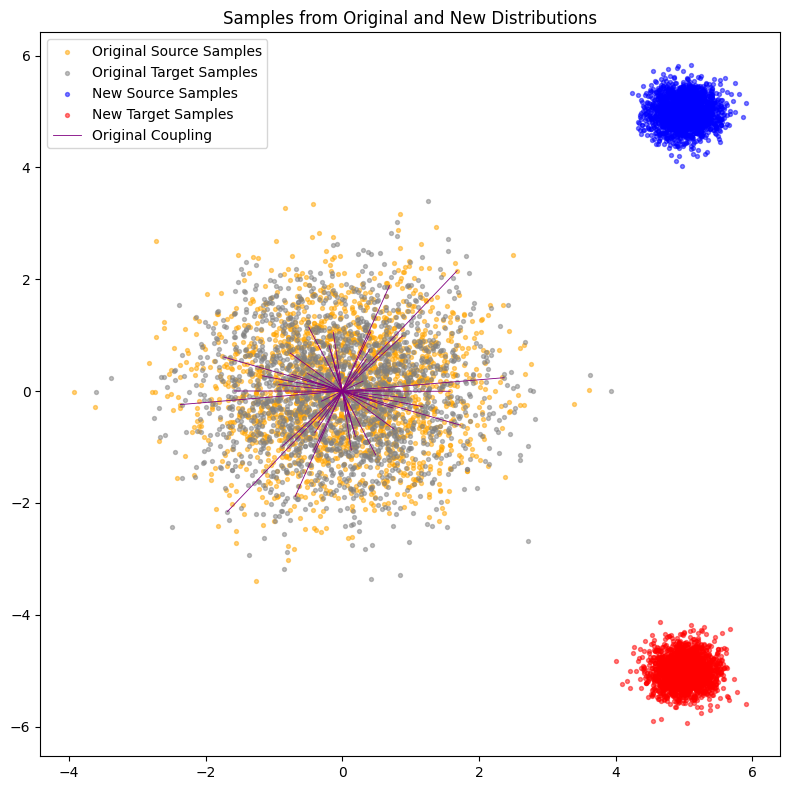

In [27]:
def anticorrelate(n: int):
    source_samples = torch.randn(n, 2)
    return source_samples, -source_samples

coupling_dist = FunctionalCouplingDistribution(anticorrelate)
source_dist, target_dist = coupling_dist.get_marginals()
new_source_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, 5.0]), std=torch.tensor([0.25, 0.25]))
new_target_dist = Simple2DGaussianDistribution(mean=torch.tensor([5.0, -5.0]), std=torch.tensor([0.25, 0.25]))

# coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(0.0, 0.0),
#     target_shift=(0.0, 0.0),
#     device=device
# )
# new_coupling_dist = RotatedShapeCoupling(
#     centers=[[0,0], [1.5,0], [-1.5,0], [0,1.5], [0,-1.5]],
#     source_scale=0.2,
#     target_scale=0.2,
#     rotation_degrees=90.0,
#     source_shift=(2.5, 2.5),
#     target_shift=(2.5, -2.5),
# )
# source_dist, target_dist = coupling_dist.get_marginals()
# new_source_dist, new_target_dist = new_coupling_dist.get_marginals()

plt.figure(figsize=(8, 8))
n_samples = 2000
coupling_samples = coupling_dist.coupling_sample(n_samples)
source_samples = coupling_samples[0].cpu().numpy()
target_samples = coupling_samples[1].cpu().numpy()
new_source_samples = new_source_dist.sample(n_samples).cpu().numpy()
new_target_samples = new_target_dist.sample(n_samples).cpu().numpy()

fig = plt.figure(figsize=(8, 8))
plt.scatter(source_samples[:, 0], source_samples[:, 1], c='orange', s=8, alpha=0.5, label='Original Source Samples')
plt.scatter(target_samples[:, 0], target_samples[:, 1], c='grey', s=8, alpha=0.5, label='Original Target Samples')
plt.scatter(new_source_samples[:, 0], new_source_samples[:, 1], c='blue', s=8, alpha=0.5, label='New Source Samples')
plt.scatter(new_target_samples[:, 0], new_target_samples[:, 1], c='red', s=8, alpha=0.5, label='New Target Samples')
plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=1.0, lw=0.6, label='Original Coupling')
plt.title('Samples from Original and New Distributions')
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.tight_layout()
plt.show()

## Learn marginal Conditional Flow Matching

Training Marginal Bridges: 100%|██████████| 2500/2500 [00:12<00:00, 199.12it/s, Loss mu=0.419, Loss nu=0.414]


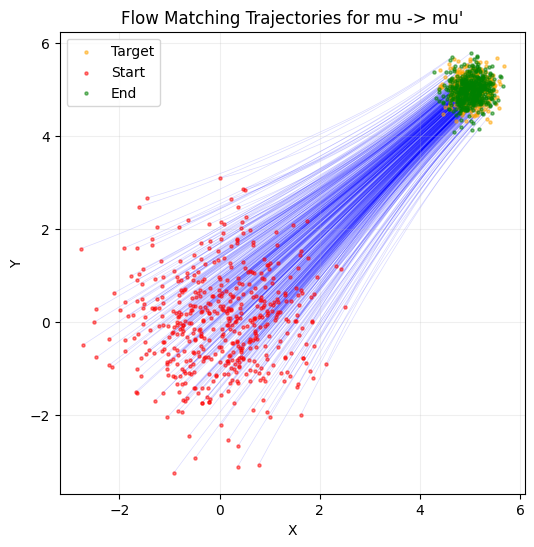

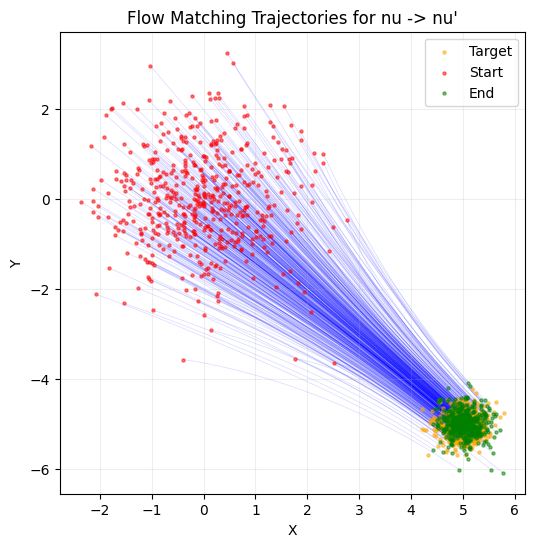

In [14]:
flow_mu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)
flow_nu = MLP(dim=2, out_dim=2, w=64, time_varying=True).to(device)

optimizer_mu = optim.Adam(flow_mu.parameters(), lr=1e-3)
optimizer_nu = optim.Adam(flow_nu.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

batch_size = 2048
epochs_marginal = 2500
sigma = 0.1

def interpolate(x0, x1, t, sigma):
    return (1 - t) * x0 + t * x1 + sigma * torch.randn_like(x0) * torch.sqrt(t * (1 - t))

pbar = trange(epochs_marginal, desc="Training Marginal Bridges")
for epoch in pbar:
    x0, y0 = coupling_dist.coupling_sample(batch_size)
    x1, y1 = new_source_dist.sample(batch_size), new_target_dist.sample(batch_size)
    x0, x1, y0, y1 = x0.to(device), x1.to(device), y0.to(device), y1.to(device)

    t = torch.rand(batch_size, 1).to(device)
    xt, yt = interpolate(x0, x1, t, sigma), interpolate(y0, y1, t, sigma)

    u_t, v_t = flow_mu(torch.cat([xt, t], dim=1)), flow_nu(torch.cat([yt, t], dim=1))
    target_u_t, target_v_t = x1 - x0, y1 - y0

    optimizer_mu.zero_grad()
    optimizer_nu.zero_grad()

    loss_mu = loss_fn(u_t, target_u_t)
    loss_mu.backward()
    optimizer_mu.step()

    loss_nu = loss_fn(v_t, target_v_t)
    loss_nu.backward()
    optimizer_nu.step()

    pbar.set_postfix({"Loss mu": loss_mu.item(), "Loss nu": loss_nu.item()})


cfm_mu = ConditionalFlowMatching(source_dist, new_source_dist, flow_mu, sigma=sigma)
cfm_nu = ConditionalFlowMatching(target_dist, new_target_dist, flow_nu, sigma=sigma)

n_samples = 500
n_timesteps = 20

time = torch.linspace(0, 1, n_timesteps)
traj_mu = cfm_mu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
traj_nu = cfm_nu.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
target_mu_samples = new_source_dist.sample(n_samples).cpu().numpy()
target_nu_samples = new_target_dist.sample(n_samples).cpu().numpy()

plot_2d_flow_trajectories(trajectories=traj_mu, t=time, n_trajectories=n_samples, target_points=target_mu_samples, title=f"Flow Matching Trajectories for mu -> mu'")
plot_2d_flow_trajectories(trajectories=traj_nu, t=time, n_trajectories=n_samples, target_points=target_nu_samples, title=f"Flow Matching Trajectories for nu -> nu'")

## Testing coupling evolution

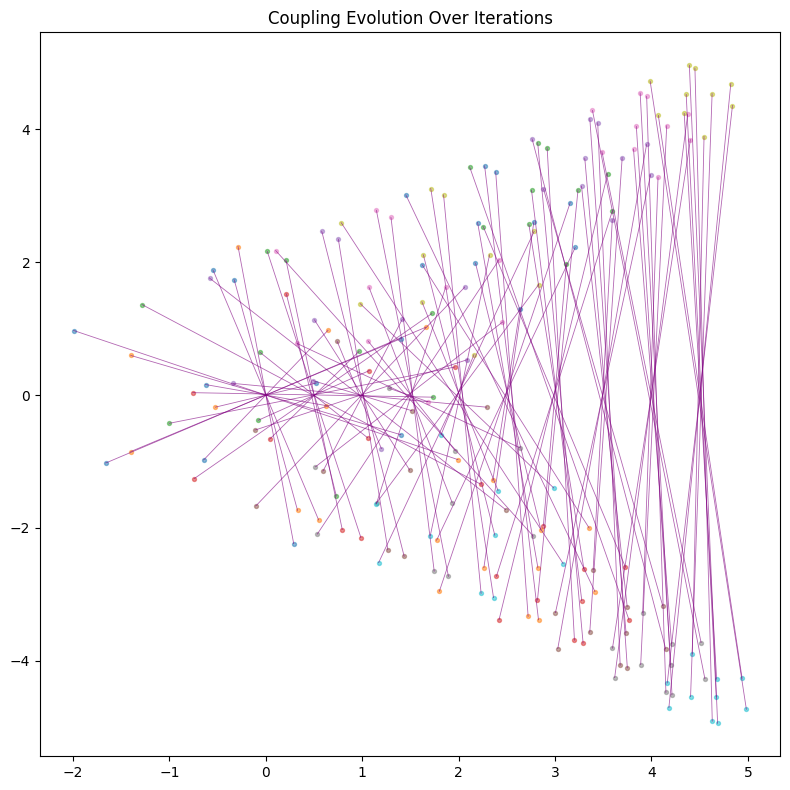

In [15]:
dataset_size = 10
current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu() # (2, dataset_size, dim)

n_iterations = 10
delta = 1.0 / n_iterations

trajectories = [current_coupling_dist.dataset.clone().cpu().numpy()]

for iteration in range(n_iterations):
    t_current = iteration / n_iterations
    x, y = current_coupling_dist.dataset[0].to(device), current_coupling_dist.dataset[1].to(device)

    t_tensor = torch.full((x.shape[0], 1), t_current).to(device)

    u_t = flow_mu(torch.cat([x, t_tensor], dim=1))
    v_t = flow_nu(torch.cat([y, t_tensor], dim=1))

    x_next = x.detach() + delta * u_t
    y_next = y.detach() + delta * v_t

    x_next = x_next.detach().cpu()
    y_next = y_next.detach().cpu()

    current_coupling_dist.dataset = torch.stack([x_next, y_next], dim=0)

    trajectories.append(current_coupling_dist.dataset.clone().cpu().numpy())

fig = plt.figure(figsize=(8, 8))
for i in range(len(trajectories)-1):
    source_samples = trajectories[i][0]
    target_samples = trajectories[i][1]
    plt.scatter(source_samples[:, 0], source_samples[:, 1], s=8, alpha=0.5, label=f'Source Samples t={i}')
    plt.scatter(target_samples[:, 0], target_samples[:, 1], s=8, alpha=0.5, label=f'Target Samples t={i}')
    plt.plot([source_samples[:25, 0], target_samples[:25, 0]], [source_samples[:25, 1], target_samples[:25, 1]], c='purple', alpha=0.6, lw=0.6)
plt.title('Coupling Evolution Over Iterations')
plt.tight_layout()
plt.show()

## Learn weights

CFM Loss: 87.1811: 100%|██████████| 1000/1000 [00:07<00:00, 139.33it/s] 


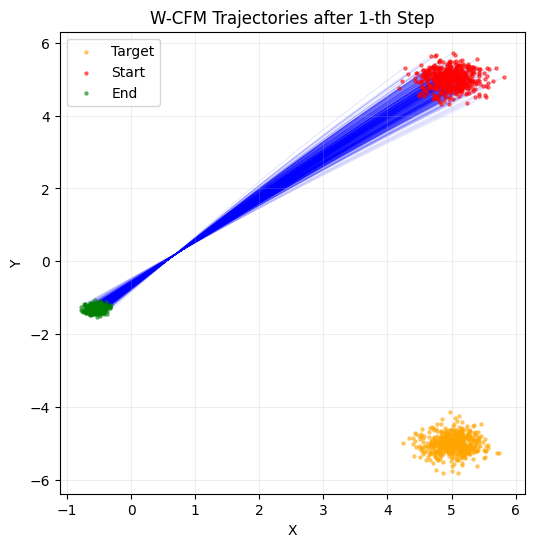

CFM Loss: 31.7850: 100%|██████████| 1000/1000 [00:07<00:00, 132.33it/s]


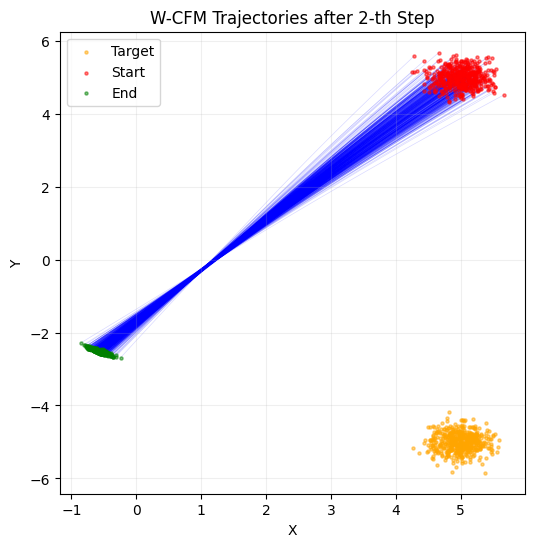

CFM Loss: 14.9524: 100%|██████████| 1000/1000 [00:05<00:00, 182.62it/s]


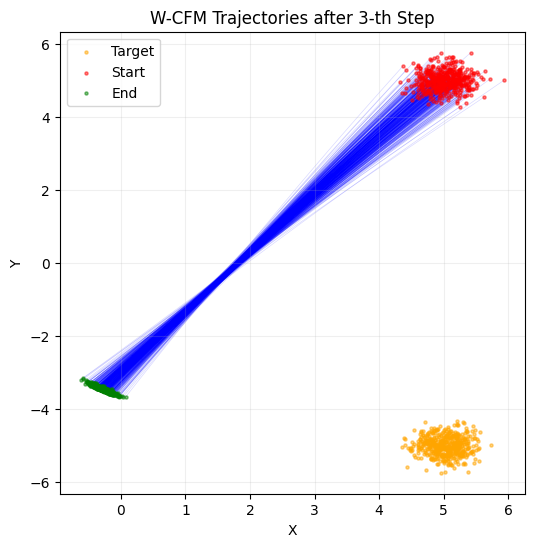

CFM Loss: 7.7058: 100%|██████████| 1000/1000 [00:05<00:00, 183.00it/s]


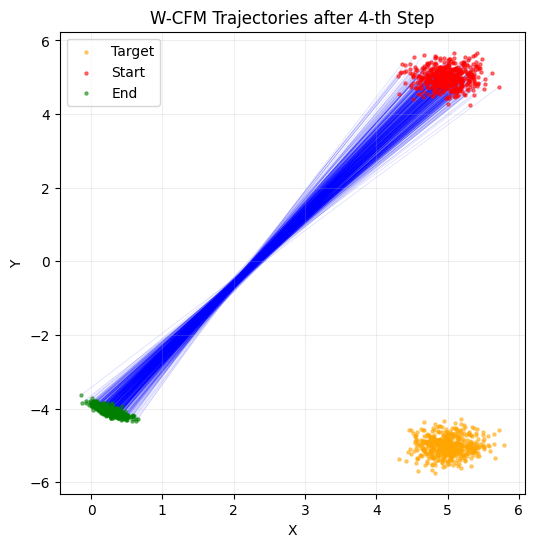

CFM Loss: 6.2380: 100%|██████████| 1000/1000 [00:05<00:00, 174.84it/s]


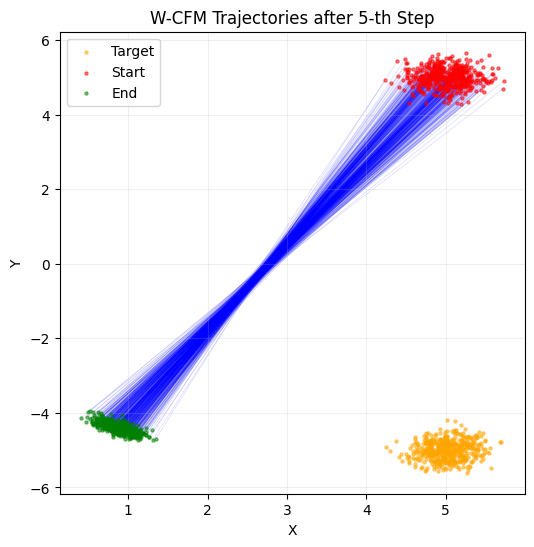

CFM Loss: 5.1555: 100%|██████████| 1000/1000 [00:05<00:00, 178.79it/s]


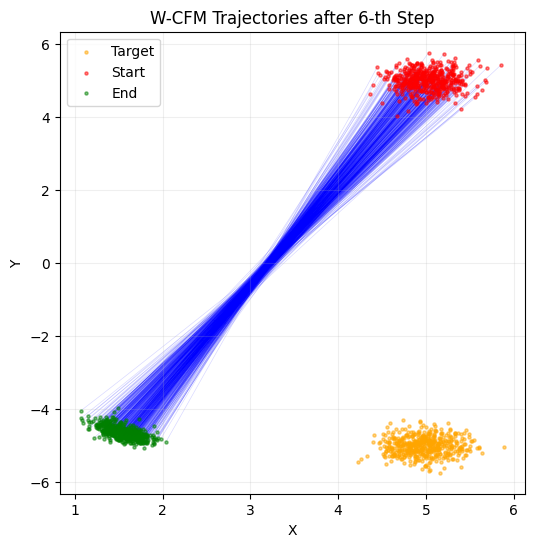

CFM Loss: 4.5317: 100%|██████████| 1000/1000 [00:05<00:00, 180.86it/s]


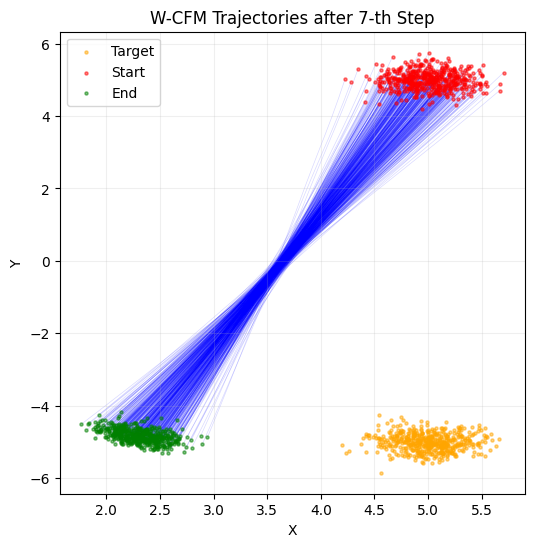

CFM Loss: 2.9990: 100%|██████████| 1000/1000 [00:05<00:00, 175.47it/s]


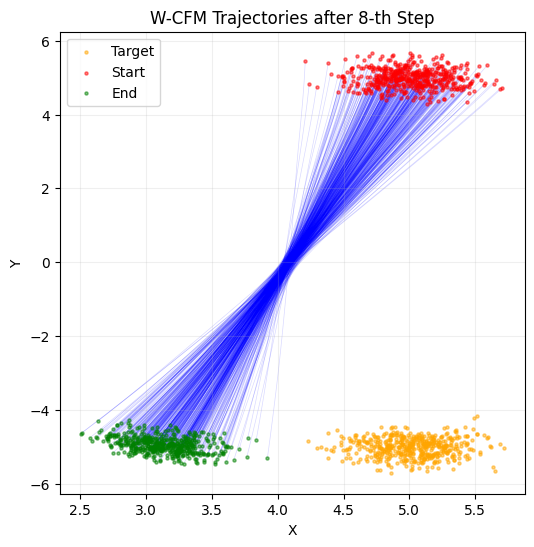

CFM Loss: 2.7790: 100%|██████████| 1000/1000 [00:05<00:00, 174.20it/s]


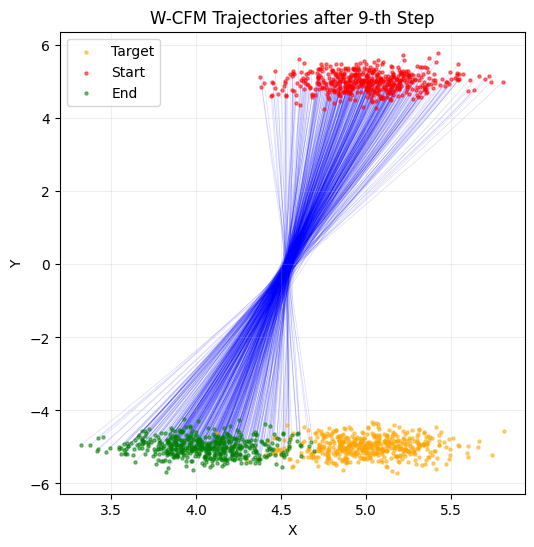

CFM Loss: 2.6087: 100%|██████████| 1000/1000 [00:05<00:00, 176.58it/s]


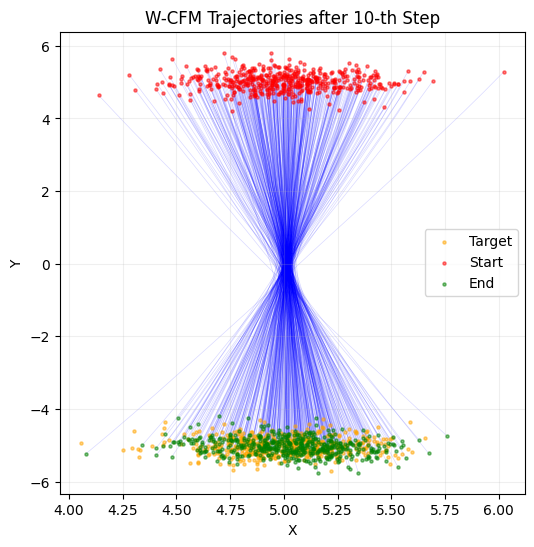

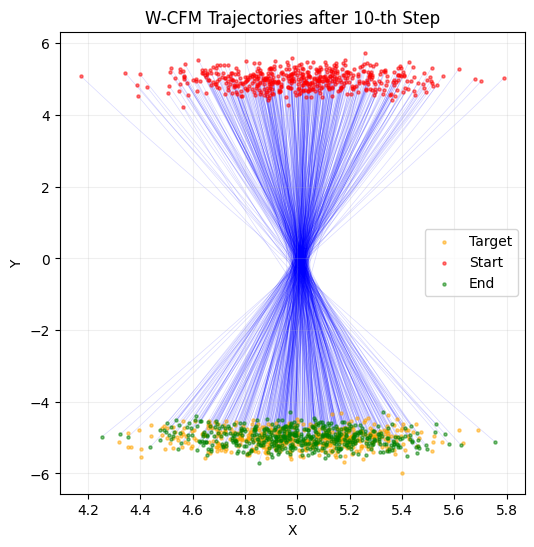

In [37]:
n_iterations = 10
epochs_dual_per_step = 200
epochs_cfm_per_step = 1000

delta = 1.0 / n_iterations
dataset_size = 1_000_000
batch_size = 2048

current_coupling_dist = FixedSizeCouplingDistribution(coupling_dist, size=dataset_size)
current_coupling_dist.dataset = current_coupling_dist.dataset.clone().cpu()

f_net = MLP(dim=2, out_dim=1, w=16, time_varying=True).to(device)
g_net = MLP(dim=2, out_dim=1, w=16, time_varying=True).to(device)

# flow_model = MLP(dim=2, out_dim=2, w=32, time_varying=True).to(device)
base_flow_model = MLP(dim=4, out_dim=2, w=64, time_varying=True)
flow_model = LagrangianFlowField(net=base_flow_model, dim=2).to(device)

optimizer_dual = optim.Adam(list(f_net.parameters()) + list(g_net.parameters()), lr=1e-4)
cfm_optimizer = optim.Adam(flow_model.parameters(), lr=1e-4)

for step in range(n_iterations):
    t_current = step * delta
    t = torch.full((batch_size, 1), t_current).to(device)

    # 2. Advance particles to create pi_{t+delta} from pi_t and flow_mu, flow_nu
    chunks = 10_000
    with torch.no_grad():
        for i in range(0, dataset_size, chunks):
            samples = current_coupling_dist.dataset[:, i:i+chunks]
            x, y = samples[0].to(device), samples[1].to(device)

            t_tensor = torch.full((x.shape[0], 1), t_current).to(device)

            u_t = flow_mu(torch.cat([x, t_tensor], dim=1))
            v_t = flow_nu(torch.cat([y, t_tensor], dim=1))

            x_next = x.detach() + delta * u_t
            y_next = y.detach() + delta * v_t

            # Detach to free graph for next step
            x_next = x_next.detach().cpu()
            y_next = y_next.detach().cpu()

            current_coupling_dist.dataset[:, i:i+chunks] = torch.stack([x_next, y_next], dim=0)

    f_net.train()
    g_net.train()

    pbar = trange(epochs_dual_per_step)
    for _ in pbar:
        x, y = current_coupling_dist.coupling_sample(batch_size)
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            u_t = flow_mu(torch.cat([x, t], dim=1))
            v_t = flow_nu(torch.cat([y, t], dim=1))

        x.requires_grad_(True)
        y.requires_grad_(True)

        a = f_net(torch.cat([x, t], dim=1))
        b = g_net(torch.cat([y, t], dim=1))

        # Loss computation (Variational)
        term_coupling = torch.mean((a - a.mean() + b - b.mean())**2)

        # Divergence terms
        grad_a = torch.autograd.grad(a.sum(), x, create_graph=True, retain_graph=True, only_inputs=True)[0]
        term_flow_a = torch.mean(torch.sum(grad_a * u_t, dim=1))

        grad_b = torch.autograd.grad(b.sum(), y, create_graph=True, retain_graph=True, only_inputs=True)[0]
        term_flow_b = torch.mean(torch.sum(grad_b * v_t, dim=1))

        loss = 0.5 * term_coupling - term_flow_a - term_flow_b

        optimizer_dual.zero_grad()
        loss.backward()
        optimizer_dual.step()

        pbar.set_description(f"Dual Loss: {loss.item():.4f}")

    # 3. Learn weighted-CFM at next step
    flow_model.train()
    f_net.eval()
    g_net.eval()

    cfm_scheduler = optim.lr_scheduler.CosineAnnealingLR(cfm_optimizer, T_max=epochs_cfm_per_step)

    pbar = trange(epochs_cfm_per_step)
    for _ in pbar:
        x0, x1 = current_coupling_dist.coupling_sample(batch_size)
        x0, x1 = x0.to(device), x1.to(device)

        s = torch.rand(batch_size, 1).to(device)
        xs = interpolate(x0, x1, s, sigma)

        # u_s = flow_model(torch.cat([xs, s], dim=1))
        u_s = flow_model(torch.cat([xs, x0, s], dim=1))
        # target_u_s = x1 - x0
        target_u_s = torch.cat([x1 - x0, torch.zeros_like(x0)], dim=1)

        with torch.no_grad():
            a, b = f_net(torch.cat([x0, t], dim=1)), g_net(torch.cat([x1, t], dim=1)) # Not the same t
            log_w = (a + b) * delta
            log_w = log_w - log_w.max()
            weight = torch.exp(log_w)
            weight = weight / (weight.mean() + 1e-8)
            weight = torch.clamp(weight, max=50.0)

        loss = torch.sum(weight * torch.sum((u_s - target_u_s)**2, dim=1, keepdim=True))

        cfm_optimizer.zero_grad()
        loss.backward()
        cfm_optimizer.step()
        # cfm_scheduler.step()

        pbar.set_description(f"CFM Loss: {loss.item():.4f}")

    # 4. Visualize learned W-CFM at current step
    flow_model.eval()
    with torch.no_grad():
        cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model, sigma=0)
        n_samples = 500
        n_timesteps = 20
        time = torch.linspace(0, 1, n_timesteps)
        x_init = new_source_dist.sample(n_samples).to(device)
        x_init_extended = torch.cat([x_init, x_init], dim=1)
        traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
        target_samples = new_target_dist.sample(n_samples).cpu().numpy()

        plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")


flow_model.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model, sigma=0)
    n_samples = 500
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init = new_source_dist.sample(n_samples).to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    # traj = cfm.get_trajectory(n_samples=n_samples, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, target_points=target_samples, title=f"W-CFM Trajectories after {step+1}-th Step")


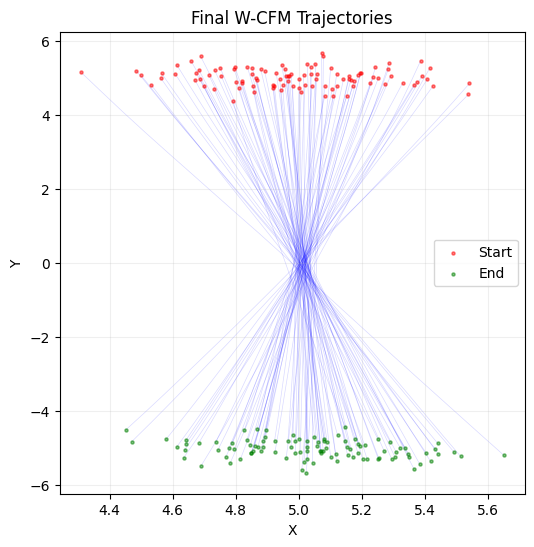

In [40]:

flow_model.eval()
with torch.no_grad():
    cfm = ConditionalFlowMatching(new_source_dist, new_target_dist, flow_model, sigma=0)
    n_samples = 100
    n_timesteps = 20
    time = torch.linspace(0, 1, n_timesteps)
    x_init = new_source_dist.sample(n_samples).to(device)
    x_init_extended = torch.cat([x_init, x_init], dim=1)
    traj = cfm.get_trajectory(x0=x_init_extended, n_timesteps=n_timesteps)
    target_samples = new_target_dist.sample(n_samples).cpu().numpy()

    plot_2d_flow_trajectories(trajectories=traj, t=time, n_trajectories=n_samples, title=f"Final W-CFM Trajectories")
